# Proiect #1: Churn la Telco (clasificare)
Autor: Claudiu-Alexandru Cirjan

Setul de date: Telco Customer Churn (Kaggle), 7.043 de clienți. Prezicem dacă un client părăsește operatorul (`Churn`).

> Fișierul `WA_Fn-UseC_-Telco-Customer-Churn.csv` trebuie încărcat în Colab (folderul din stânga) înainte de rulare.

## Pasul 1: Explorarea datelor

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)  # (rânduri, coloane)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()  # tipurile coloanelor
print(df.isnull().sum())  # valori lipsă (NaN)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
# TotalCharges apare ca text; spațiile goale nu sunt văzute de isnull().
# Le transformăm în NaN ca să le vedem.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges lipsă:", df["TotalCharges"].isnull().sum())
print(df[df["TotalCharges"].isnull()][["tenure", "TotalCharges"]].head())

TotalCharges lipsă: 11
      tenure  TotalCharges
488        0           NaN
753        0           NaN
936        0           NaN
1082       0           NaN
1340       0           NaN


In [4]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


### Graficele (câte o propoziție de la tine sub fiecare)

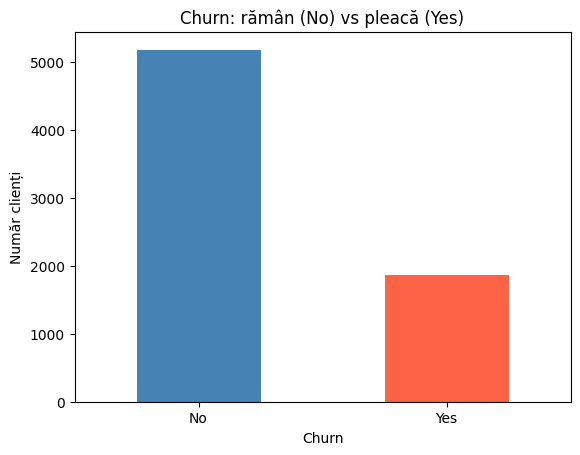

In [5]:
# Grafic 1: câți clienți pleacă vs rămân
df["Churn"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Churn: rămân (No) vs pleacă (Yes)")
plt.ylabel("Număr clienți")
plt.xticks(rotation=0)
plt.show()

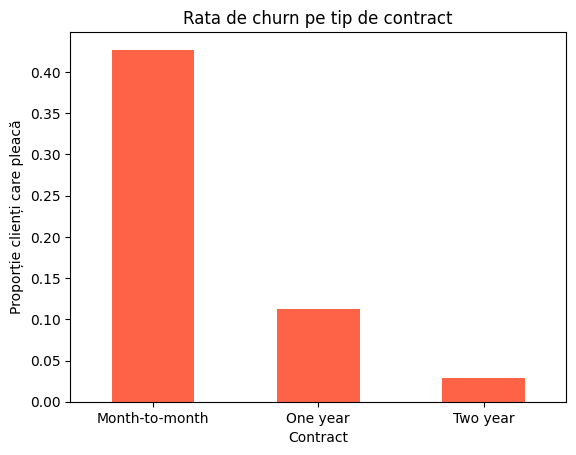

In [6]:
# Grafic 2: rata de churn în funcție de tipul de contract
rata = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean())
rata.plot(kind="bar", color="tomato")
plt.title("Rata de churn pe tip de contract")
plt.ylabel("Proporție clienți care pleacă")
plt.xticks(rotation=0)
plt.show()

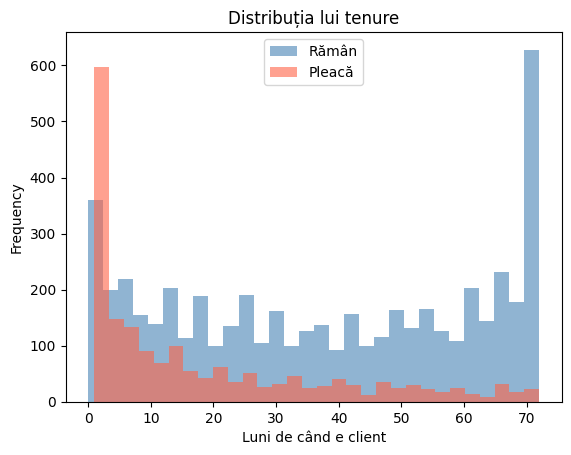

In [7]:
# Grafic 3: distribuția lui tenure (luni de când e client) pentru cei care pleacă vs rămân
df[df["Churn"] == "No"]["tenure"].plot(kind="hist", bins=30, alpha=0.6, label="Rămân", color="steelblue")
df[df["Churn"] == "Yes"]["tenure"].plot(kind="hist", bins=30, alpha=0.6, label="Pleacă", color="tomato")
plt.title("Distribuția lui tenure")
plt.xlabel("Luni de când e client")
plt.legend()
plt.show()

## Pasul 2: Pregătirea datelor

In [8]:
from sklearn.model_selection import train_test_split

# customerID e doar un identificator, nu ajută la predicție
X = df.drop(columns=["customerID", "Churn"])
y = (df["Churn"] == "Yes").astype(int)  # 1 = pleacă, 0 = rămâne

# stratify=y păstrează aceeași proporție de churn în train și test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numerice:", num_cols)
print("Text:", cat_cols)

# numerice: completăm lipsurile cu mediana, apoi scalăm
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
# text: One-Hot Encoding (fiecare categorie devine o coloană 0/1)
preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
# Preprocesarea se învață (fit) doar pe train, în interiorul pipeline-urilor de mai jos

Numerice: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Text: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Pasul 3: Baseline

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")  # prezice mereu clasa majoritară
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_dummy))
print("Recall:", recall_score(y_test, pred_dummy))
print("F1:", f1_score(y_test, pred_dummy))

Accuracy: 0.7345635202271115
Recall: 0.0
F1: 0.0


## Pasul 4: Modelele

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_reg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])
rf = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(n_estimators=300, random_state=42)),
])

log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("Modele antrenate")

Modele antrenate


## Pasul 5: Evaluare pe setul de test

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

modele = {"Baseline (Dummy)": dummy, "Regresie logistică": log_reg, "Random Forest": rf}
rezultate = []
for nume, m in modele.items():
    p = m.predict(X_test)
    rezultate.append({
        "Model": nume,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, zero_division=0),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    })
pd.DataFrame(rezultate).round(3)

,Model,Accuracy,Precision,Recall,F1
0,Baseline (Dummy),0.735,0.000,0.000,0.000
1,Regresie logistică,0.806,0.657,0.559,0.604
2,Random Forest,0.779,0.606,0.473,0.532


===== Regresie logistică =====
              precision    recall  f1-score   support

      Rămâne       0.85      0.89      0.87      1035
      Pleacă       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



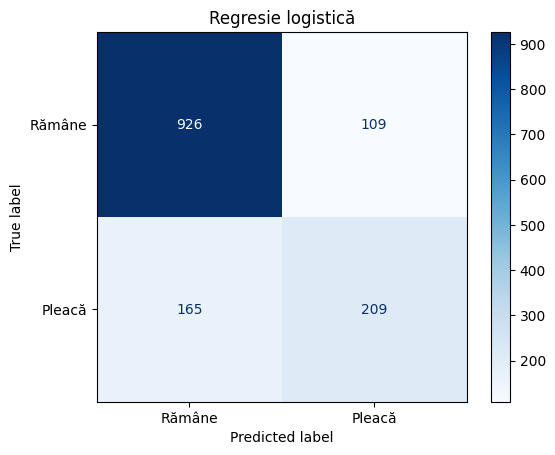

===== Random Forest =====
              precision    recall  f1-score   support

      Rămâne       0.82      0.89      0.86      1035
      Pleacă       0.61      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



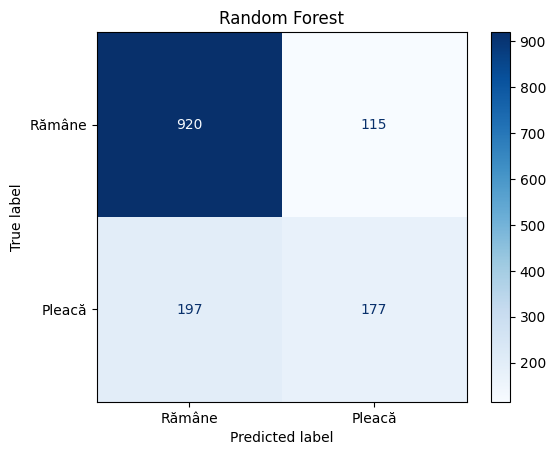

In [13]:
for nume, m in [("Regresie logistică", log_reg), ("Random Forest", rf)]:
    p = m.predict(X_test)
    print("=====", nume, "=====")
    print(classification_report(y_test, p, target_names=["Rămâne", "Pleacă"]))
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Rămâne", "Pleacă"]).plot(cmap="Blues")
    plt.title(nume)
    plt.show()

## Pasul 6: Concluzie



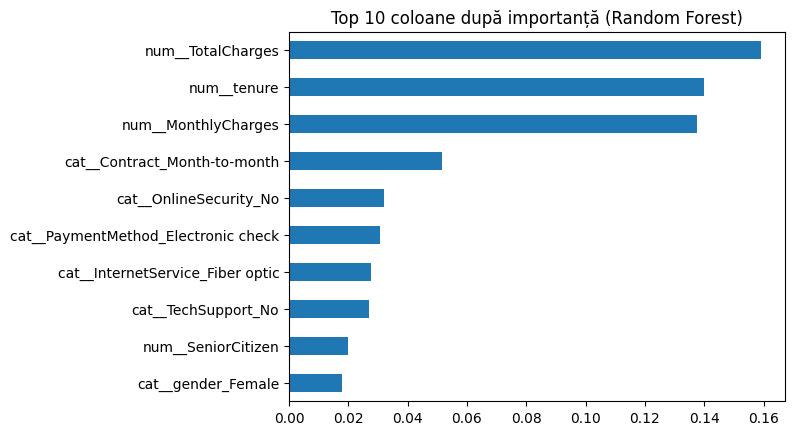

In [14]:
nume_col = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=nume_col)
imp.sort_values().tail(10).plot(kind="barh")
plt.title("Top 10 coloane după importanță (Random Forest)")
plt.show()